In [1]:
import numpy as np
import pandas as pd


from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, f1_score, precision_score, recall_score

import torch
from torch import nn
from torch.nn import functional as F




from IPython import display
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.base import BaseEstimator

out_dict = dict()
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
# __________end of block__________

In [2]:
from ml.dataset.dataset import BoostDatasetWindow


from tqdm import tqdm

In [3]:
def plot_train_process(train_loss, val_loss, train_f1, val_f1, train_rec, val_rec, train_pres, val_pres, title_suffix=''):
    fig, axes = plt.subplots(1, 4, figsize=(30, 5))

    axes[0].set_title(' '.join(['Loss', title_suffix]))
    axes[0].plot(train_loss, label='train')
    axes[0].plot(val_loss, label='validation')
    axes[0].legend()

    axes[1].set_title(' '.join(['Validation f1', title_suffix]))
    axes[1].plot(train_f1, label='train')
    axes[1].plot(val_f1, label='validation')
    axes[1].legend()
    
    axes[2].set_title(' '.join(['Validation recall', title_suffix]))
    axes[2].plot(train_rec, label='train')
    axes[2].plot(val_rec, label='validation')
    axes[2].legend()
    
    axes[3].set_title(' '.join(['Validation precision', title_suffix]))
    axes[3].plot(train_pres, label='train')
    axes[3].plot(val_pres, label='validation')
    axes[3].legend()
    plt.show()

def visualize_and_save_results(model, model_name, X_train, X_test, y_train, y_test, out_dict):
    for data_name, X, y, model in [
    ('train', X_train, y_train, model),
    ('test', X_test, y_test, model)
    ]:
        if isinstance(model, BaseEstimator):
            proba = model.predict_proba(X)[:, 1]
        elif isinstance(model, nn.Module):
            proba = model(X).detach().cpu().numpy()[:, 1]
        else:
            raise ValueError('Unrecognized model type')

        auc = roc_auc_score(y, proba)

        out_dict['{}_{}'.format(model_name, data_name)] = auc
        plt.plot(*roc_curve(y, proba)[:2], label='%s AUC=%.4f' % (data_name, auc))

    plt.plot([0, 1], [0, 1], '--', color='black',)
    plt.legend(fontsize='large')
    plt.title(model_name)
    plt.grid()
    return out_dict

In [4]:
dataset = BoostDatasetWindow()
train_size = int(0.7 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_data, val_data, test_data = torch.utils.data.random_split(dataset, [train_size, val_size, test_size])

train_loader = torch.utils.data.DataLoader(train_data, batch_size=256, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_data, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=64, shuffle=True)

In [5]:
class PeaksModel(nn.Module):

    def __init__(self, num_channels=5, num_features=396):
        super(PeaksModel, self).__init__()
        self.conv1 = nn.Conv1d(num_channels, 128, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm1d(128)
        self.conv2 = nn.Conv1d(128, 256, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm1d(256)
        self.conv3 = nn.Conv1d(256, 512, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm1d(512)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(512 * num_features, 2)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.dropout(x)
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.dropout(x)
        x = x.view(x.size(0), -1)
        x = self.sigmoid(self.fc(x))
        return x


model = PeaksModel()
model = model.to(device)

In [6]:
loss_function = nn.CrossEntropyLoss(weight=torch.tensor([0.5, 1.5]).to(device))
#optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.8)

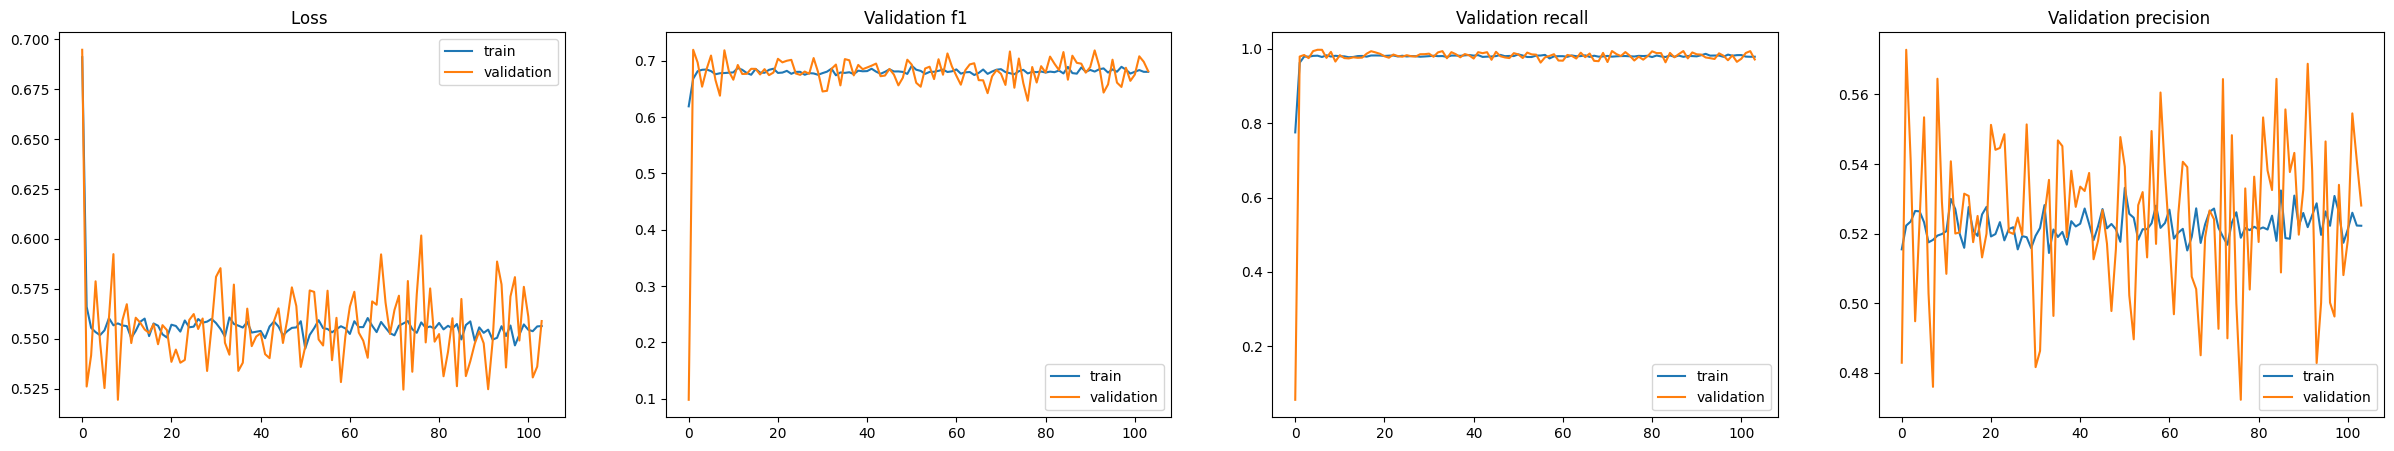

In [7]:
train_loss_history = []
train_f1_history = []
train_rec_history = []
train_pres_history = []
val_loss_history = []
val_f1_history = []
val_rec_history = []
val_pres_history = []


local_train_loss_history = []
local_train_f1_history = []
local_train_rec_history = []
local_train_pres_history = []
eval_every=50
i = 0


for  x, y in train_loader:
    x = x.to(device).float()
    y = y.to(device).long()
    optimizer.zero_grad()
    pred = model(x)
    loss = loss_function(pred, y)
    loss.backward()
    optimizer.step()
    local_train_loss_history.append(loss.item())
    local_train_f1_history.append(f1_score(y.cpu().numpy(), pred.argmax(dim=1).cpu().numpy()))
    local_train_rec_history.append(recall_score(y.cpu().numpy(), pred.argmax(dim=1).cpu().numpy()))
    local_train_pres_history.append(precision_score(y.cpu().numpy(), pred.argmax(dim=1).cpu().numpy()))
    
    if i % eval_every == 0:
        train_loss_history.append(np.mean(local_train_loss_history))
        train_f1_history.append(np.mean(local_train_f1_history))
        train_rec_history.append(np.mean(local_train_rec_history))
        train_pres_history.append(np.mean(local_train_pres_history))
        
        local_train_loss_history = []
        local_train_f1_history = []
        local_train_rec_history = []
        local_train_pres_history = []
        
        with torch.no_grad():
            model.eval()
            local_val_loss_history = []
            local_val_f1_history = []
            local_val_rec_history = []
            local_val_pres_history = []
            k = 0
            for x, y in val_loader:
                x = x.to(device).float()
                y = y.to(device).long()
                pred = model(x)
                loss = loss_function(pred, y)
                local_val_loss_history.append(loss.item())
                local_val_f1_history.append(f1_score(y.cpu().numpy(), pred.argmax(dim=1).cpu().numpy()))
                local_val_rec_history.append(recall_score(y.cpu().numpy(), pred.argmax(dim=1).cpu().numpy()))
                local_val_pres_history.append(precision_score(y.cpu().numpy(), pred.argmax(dim=1).cpu().numpy()))
                k+=1
                if k == 10:
                    break
                
            val_loss_history.append(np.mean(local_val_loss_history))
            val_f1_history.append(np.mean(local_val_f1_history))
            val_rec_history.append(np.mean(local_val_rec_history))
            val_pres_history.append(np.mean(local_val_pres_history))
            display.clear_output(wait=True)
            plot_train_process(train_loss_history, val_loss_history, train_f1_history, val_f1_history, train_rec_history, val_rec_history, train_pres_history, val_pres_history)
    i+= 1